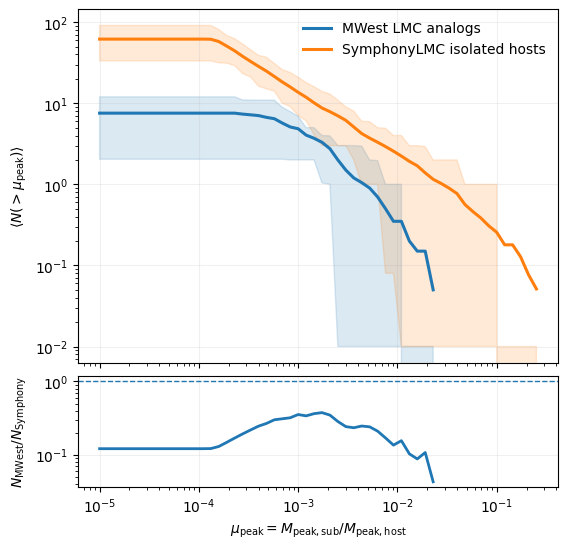

In [1]:
#fig 1
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = Path(
    "./lmc_proposal_symphony_vs_mwest/share/shmf/"
    "proposal_shmf_z2_bound_mpeak_formatted.csv"
)

df = pd.read_csv(DATA)

mu = df["mu_peak"].to_numpy()

fig, (ax, ax_ratio) = plt.subplots(
    2, 1,
    figsize=(6.2, 6.2),
    sharex=True,
    gridspec_kw={
        "height_ratios": [3.2, 1],
        "hspace": 0.06,
    },
)


for name, label in [
    ("MWest", "MWest LMC analogs"),
    ("SymphonyLMC", "SymphonyLMC isolated hosts"),
]:

    mean = df[f"{name}_mean"].to_numpy()
    p16 = df[f"{name}_p16"].to_numpy()
    p84 = df[f"{name}_p84"].to_numpy()

    good = mean > 0

    line, = ax.plot(
        mu[good],
        mean[good],
        lw=2.2,
        label=label,
    )

    ax.fill_between(
        mu[good],
        np.maximum(p16[good], 1e-2),
        p84[good],
        color=line.get_color(),
        alpha=0.16,
    )


ratio = df["MWest_over_Symphony"].to_numpy()
good = np.isfinite(ratio) & (ratio > 0)

ax_ratio.plot(
    mu[good],
    ratio[good],
    lw=2,
)

ax_ratio.axhline(
    1,
    ls="--",
    lw=1,
)


ax.set_xscale("log")
ax.set_yscale("log")

ax_ratio.set_xscale("log")
ax_ratio.set_yscale("log")

ax.set_ylabel(
    r"$\langle N(>\mu_{\rm peak})\rangle$"
)

ax_ratio.set_xlabel(
    r"$\mu_{\rm peak}=M_{\rm peak,sub}/M_{\rm peak,host}$"
)

ax_ratio.set_ylabel(
    r"$N_{\rm MWest}/N_{\rm Symphony}$"
)

ax.legend(frameon=False)

ax.grid(alpha=0.18)
ax_ratio.grid(alpha=0.18)

plt.show()

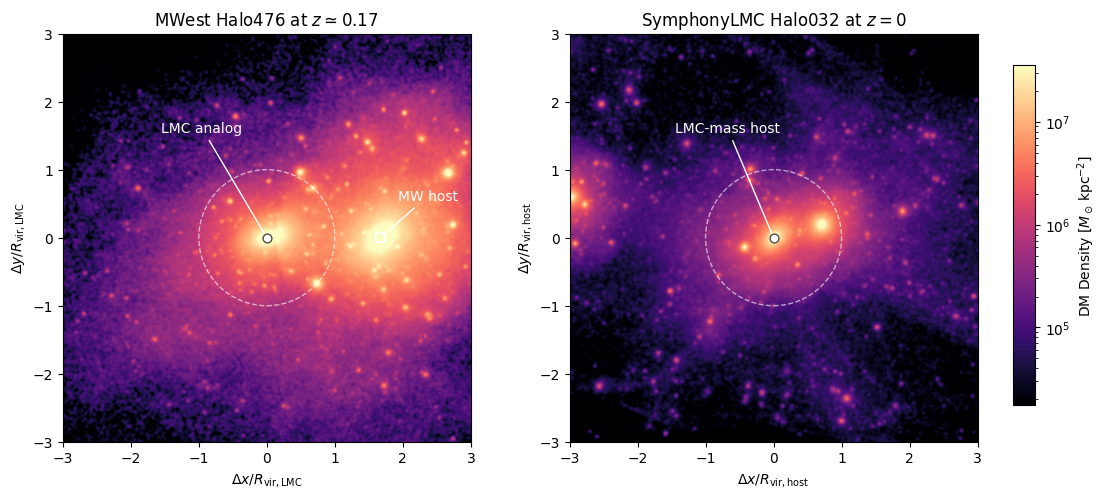

In [3]:
#fig 2
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

DATA_DIR = Path("./lmc_proposal_symphony_vs_mwest/share/environment_maps")

data = pd.read_csv(
    DATA_DIR / "MWest_Halo476_vs_SymphonyLMC_Halo032_density.csv"
)

with open(
    DATA_DIR / "MWest_Halo476_vs_SymphonyLMC_Halo032_metadata.json"
) as f:
    meta = json.load(f)


N = meta["npix"]
lim = meta["lim_rvir"]

mw = data["MWest_sigma_Msun_kpc2"].to_numpy().reshape(N, N)
sy = data["SymphonyLMC_sigma_Msun_kpc2"].to_numpy().reshape(N, N)

norm = LogNorm(
    vmin=meta["vmin"],
    vmax=meta["vmax"],
)

mw = np.maximum(mw, meta["vmin"])
sy = np.maximum(sy, meta["vmin"])


fig, ax = plt.subplots(1, 2, figsize=(12.4, 5.3))

im = ax[0].imshow(
    mw,
    origin="lower",
    extent=[-lim, lim, -lim, lim],
    cmap="magma",
    norm=norm,
    interpolation="bilinear",
)

ax[1].imshow(
    sy,
    origin="lower",
    extent=[-lim, lim, -lim, lim],
    cmap="magma",
    norm=norm,
    interpolation="bilinear",
)


# virial radii
for a in ax:
    a.add_patch(
        plt.Circle(
            (0, 0), 1,
            fill=False,
            ls="--",
            lw=1,
            color="white",
            alpha=0.6,
        )
    )

    a.scatter(
        0, 0,
        s=40,
        facecolor="white",
        edgecolor="0.3",
        zorder=5,
    )

    a.set_xlim(-lim, lim)
    a.set_ylim(-lim, lim)
    a.set_aspect("equal")


# MWest MW host
ax[0].scatter(
    meta["MWest_MW_x_over_Rvir"],
    meta["MWest_MW_y_over_Rvir"],
    s=48,
    marker="s",
    facecolor="none",
    edgecolor="white",
    lw=1.2,
)

ax[0].annotate(
    "LMC analog",
    xy=(0, 0),
    xytext=(-1.55, 1.55),
    color="white",
    arrowprops=dict(
        arrowstyle="-",
        color="white",
    ),
)

ax[0].annotate(
    "MW host",
    xy=(
        meta["MWest_MW_x_over_Rvir"],
        meta["MWest_MW_y_over_Rvir"],
    ),
    xytext=(
        meta["MWest_MW_x_over_Rvir"] + 0.25,
        meta["MWest_MW_y_over_Rvir"] + 0.55,
    ),
    color="white",
    arrowprops=dict(
        arrowstyle="-",
        color="white",
    ),
)


ax[1].annotate(
    "LMC-mass host",
    xy=(0, 0),
    xytext=(-1.45, 1.55),
    color="white",
    arrowprops=dict(
        arrowstyle="-",
        color="white",
    ),
)


ax[0].set_title(
    rf"MWest Halo476 at $z\simeq{meta['MWest_z']:.2f}$"
)

ax[1].set_title(
    r"SymphonyLMC Halo032 at $z=0$"
)


ax[0].set_xlabel(r"$\Delta x/R_{\rm vir,LMC}$")
ax[0].set_ylabel(r"$\Delta y/R_{\rm vir,LMC}$")

ax[1].set_xlabel(r"$\Delta x/R_{\rm vir,host}$")
ax[1].set_ylabel(r"$\Delta y/R_{\rm vir,host}$")


fig.subplots_adjust(
    right=0.88,
    wspace=0.18,
)

cax = fig.add_axes([0.90, 0.18, 0.018, 0.64])

cbar = fig.colorbar(im, cax=cax)

cbar.set_label(
    r"DM Density "
    r"$[M_\odot\,{\rm kpc}^{-2}]$"
)

plt.show()